導入必要套件

1. 掛載 Google Drive
在第一個儲存格貼上執行，依提示完成 Google 帳號授權：

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. 在 Google Drive 建立專案資料夾與 main.py
在第二個儲存格執行以下代碼，利用 %%writefile 直接把 Python 程式碼寫進 Google Drive 的 my_project/main.py 檔案中：

In [2]:
import os

# 建立專案資料夾
project_path = '/content/drive/MyDrive/my_project'
os.makedirs(project_path, exist_ok=True)

# 切換工作目錄到該資料夾
os.chdir(project_path)

# 寫入 main.py 檔案

In [3]:
%%writefile /content/drive/MyDrive/my_project/main.py
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

print("正在加載資料集並訓練模型...")
digits = load_digits()

# 訓練手寫數字分類模型
model = LogisticRegression(max_iter=1000).fit(digits.data, digits.target)
acc = model.score(digits.data, digits.target)

print(f"訓練完成！模型在資料集上的準確率: {acc * 100:.2f}%")

# 測試第 0 筆樣本預測
pred = model.predict(digits.data[0:1])
print(f"測試樣本預測結果: {pred[0]} (真實標籤: {digits.target[0]})")

Writing /content/drive/MyDrive/my_project/main.py


3. 切換路徑並執行 main.py
在第三個儲存格確認檔案存在，並直接用 Python 執行它：

In [4]:
import os
os.chdir('/content/drive/MyDrive/my_project')

# 查看當前目錄檔案（會看到剛剛建立的 main.py）
!ls

# 執行 python 檔案
!python main.py

main.py
正在加載資料集並訓練模型...
訓練完成！模型在資料集上的準確率: 100.00%
測試樣本預測結果: 0 (真實標籤: 0)


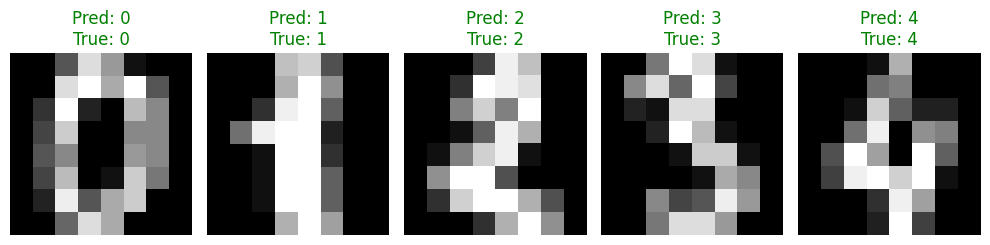

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

# 1. 載入資料並快速訓練模型
digits = load_digits()
model = LogisticRegression(max_iter=1000).fit(digits.data, digits.target)

# 2. 取前 5 張影像進行測試與畫圖
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    img = digits.data[i:i+1]
    pred = model.predict(img)[0]
    true_label = digits.target[i]

    # 繪製 8x8 灰階影像
    axes[i].imshow(digits.images[i], cmap='gray')

    # 預測正確顯示綠色標題，錯誤顯示紅色
    title_color = "green" if pred == true_label else "red"
    axes[i].set_title(f"Pred: {pred}\nTrue: {true_label}", color=title_color)
    axes[i].axis('off')

plt.tight_layout()
plt.show()